<center><h1>Satish_Manvika_HW5</h1></center>
<br>
<br>

Name: Manvika Satish
<br>
Github Username: manvsatish
<br>
USC ID: 5582061880

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path # data handling
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt # plotting
import seaborn as sns

from sklearn.impute import SimpleImputer # preprocessing& model selection
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text # classification tree
from sklearn.metrics import accuracy_score

# regression mods
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error
# boosting
from xgboost import XGBRegressor

# notebook settings
RANDOM_STATE = 552
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 150)

print("Packages imported successfully.")

Packages imported successfully.


### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
diagnosis_path = Path("../data/diagnosis.data")

#6 preds, 2 labels
diagnosis_columns = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra", "bladder_inflammation", "nephritis"]
diagnosis_raw = pd.read_csv(diagnosis_path, sep="\t", header=None, names=diagnosis_columns, encoding="utf-16", decimal=",") #tab sep utf file
print("Raw dataset shape:", diagnosis_raw.shape)
display(diagnosis_raw.head())

binary_columns = diagnosis_columns[1:] # yes/no column -> 1/0

diagnosis_data = diagnosis_raw.copy()
diagnosis_data[binary_columns] = diagnosis_data[binary_columns].replace({"no": 0, "yes": 1}).astype(int)

#verify ds before modeling
assert diagnosis_data.shape == (120, 8)
assert diagnosis_data.isna().sum().sum() == 0
assert diagnosis_data[binary_columns].isin([0, 1]).all().all()
print("Encoded dataset shape:", diagnosis_data.shape)
print("Total missing values:", diagnosis_data.isna().sum().sum())
print("\nEncoded data types:")
display(diagnosis_data.dtypes.to_frame(name="Data Type"))

print("\nFirst five encoded rows:")
display(diagnosis_data.head())

print("\nLabel combination counts:")
display(diagnosis_data[["bladder_inflammation", "nephritis"]].value_counts().sort_index().to_frame(name="Count"))

Raw dataset shape: (120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Encoded dataset shape: (120, 8)
Total missing values: 0

Encoded data types:


,Data Type
temperature,float64
nausea,int64
lumbar_pain,int64
urine_pushing,int64
micturition_pains,int64
burning_urethra,int64
bladder_inflammation,int64
nephritis,int64



First five encoded rows:


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0



Label combination counts:


Count
bladder_inflammation nephritis       
0                    0             30
                     1             31
1                    0             40
                     1             19

### (b) Build a decision tree

Label-powerset class counts:


,Count
Bladder inflammation only,40
Nephritis only,31
Neither,30
Both diagnoses,19


Tree depth: 4
Number of leaves: 6
Number of nodes: 11
Whole-dataset accuracy: 1.0


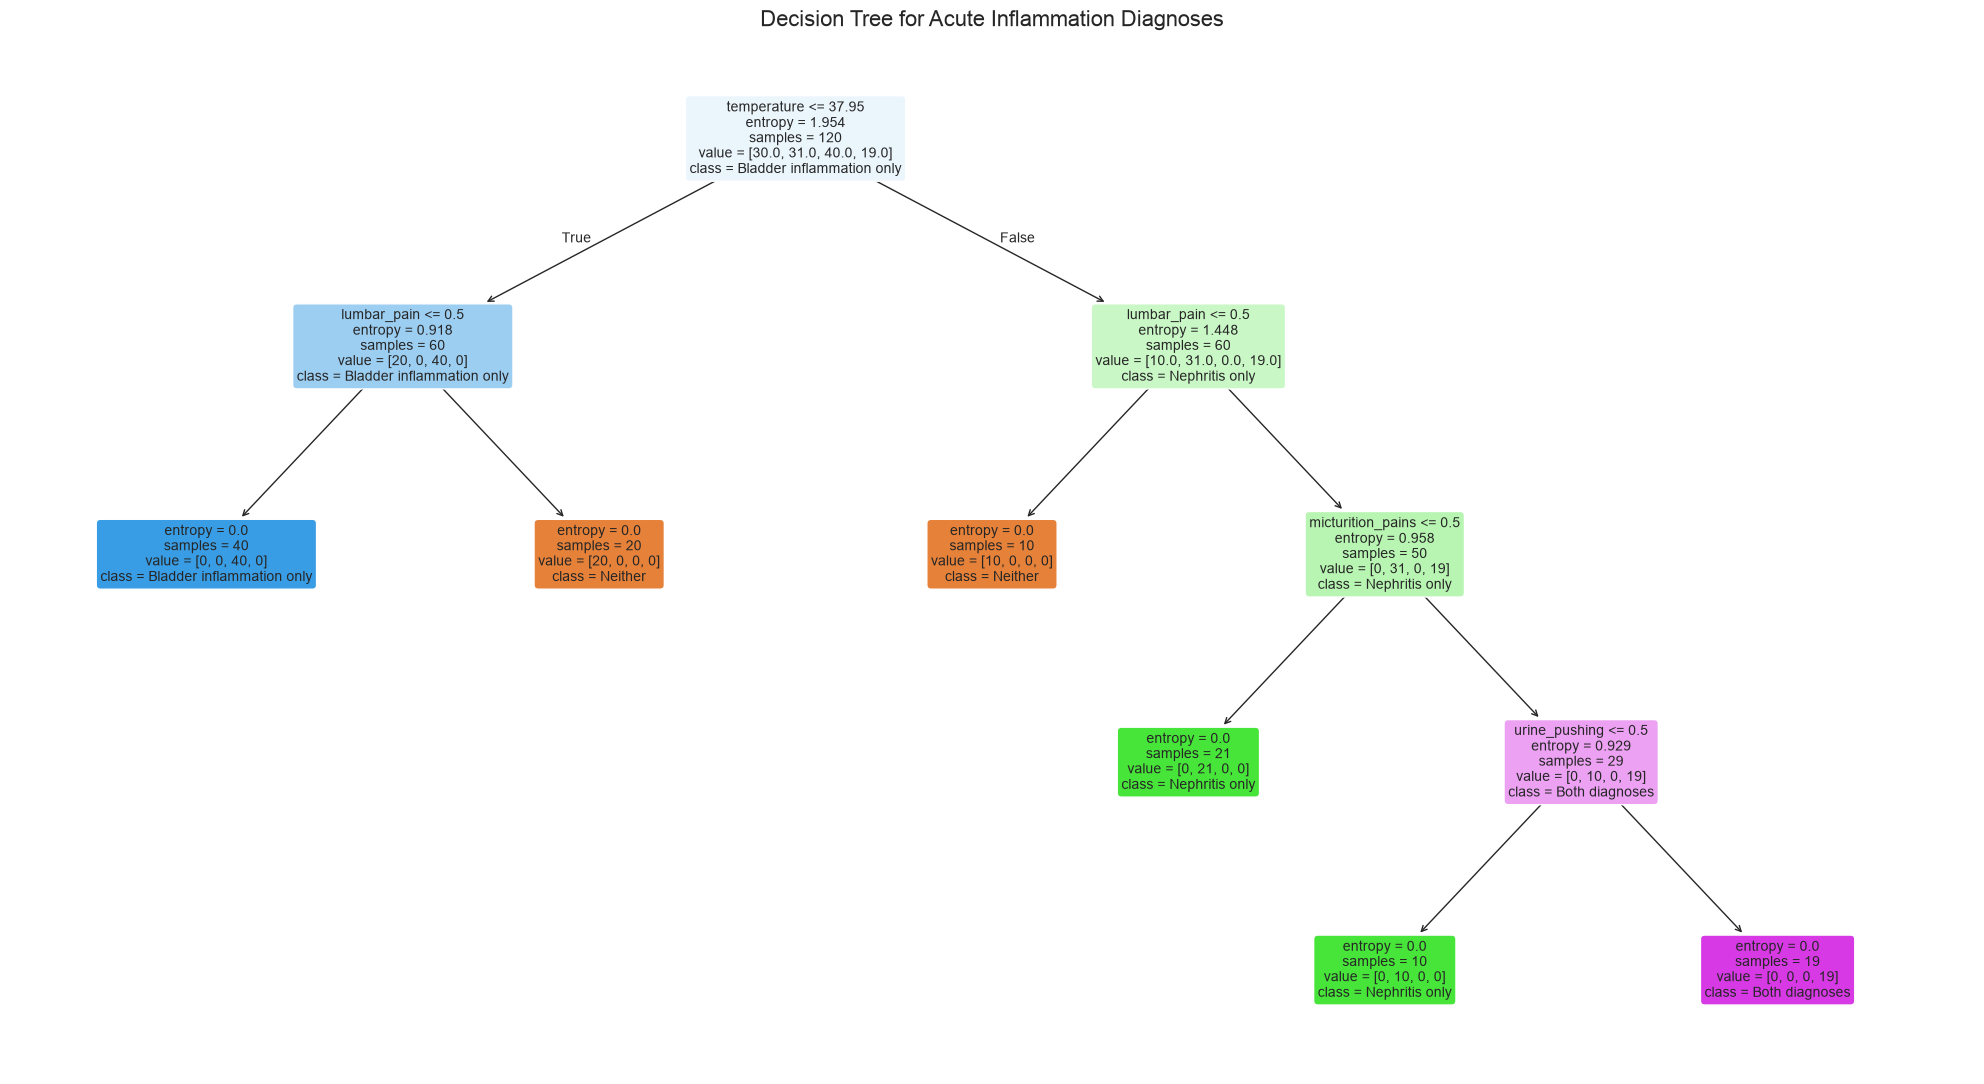

In [3]:
# sep 6 predictors from 2 diag labels
diagnosis_feature_names = ["temperature", "nausea", "lumbar_pain", "urine_pushing", "micturition_pains", "burning_urethra"]
X_diagnosis = diagnosis_data[diagnosis_feature_names].copy()
y_diagnosis = diagnosis_data[["bladder_inflammation", "nephritis"]].copy()
y_powerset = y_diagnosis.astype(str).agg("_".join, axis=1) # combine 2 bin labels into one label-powerset class

class_name_map = {"0_0": "Neither", "0_1": "Nephritis only", "1_0": "Bladder inflammation only", "1_1": "Both diagnoses"}
print("Label-powerset class counts:")
display(y_powerset.map(class_name_map).value_counts().to_frame(name="Count"))

# build decision tree on the entire ds
full_tree = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE)
full_tree.fit(X_diagnosis, y_powerset)

# calc ds predictions and accuracy
full_tree_predictions = full_tree.predict(X_diagnosis)
full_tree_accuracy = accuracy_score(y_powerset, full_tree_predictions)
print("Tree depth:", full_tree.get_depth())
print("Number of leaves:", full_tree.get_n_leaves())
print("Number of nodes:", full_tree.tree_.node_count)
print("Whole-dataset accuracy:", round(full_tree_accuracy, 4))

# create readable class names in the tree's class order
tree_class_names = [class_name_map[class_label] for class_label in full_tree.classes_]
plt.figure(figsize=(20, 11)) # plot complete decision tree

plot_tree(full_tree, feature_names=diagnosis_feature_names, class_names=tree_class_names, filled=True, rounded=True, impurity=True, proportion=False, fontsize=10)
plt.title("Decision Tree for Acute Inflammation Diagnoses", fontsize=16)
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [4]:
#follow each path from the root to leaf recursively
def recurse_if_then_rules(model, feature_names, class_map, node, conditions, rule_number):
    tree_structure = model.tree_
    feature_index = tree_structure.feature[node]
 
    if feature_index != -2:  # continue splitting if the current node is not a leaf
        feature_name = feature_names[feature_index]
        threshold = tree_structure.threshold[node]
        
        if feature_name != "temperature" and np.isclose(threshold, 0.5): # make binary conditions easier to interpret
            left_condition = f"{feature_name} = no"
            right_condition = f"{feature_name} = yes"
        else:
            left_condition = f"{feature_name} <= {threshold:.2f}"
            right_condition = f"{feature_name} > {threshold:.2f}"

        # recursive funcs
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_left[node], conditions + [left_condition], rule_number)
        rule_number = recurse_if_then_rules(model, feature_names, class_map, tree_structure.children_right[node], conditions + [right_condition], rule_number)

    # print the diagnosis when a leaf is reached
    else:
        class_index = np.argmax(tree_structure.value[node][0])
        class_code = model.classes_[class_index]
        diagnosis = class_map[class_code]
        sample_count = tree_structure.n_node_samples[node]
        print(
            f"Rule {rule_number}: IF "
            + " AND ".join(conditions)
            + f" THEN diagnosis = {diagnosis} "
            + f"(samples = {sample_count})"
        )
        rule_number += 1

    return rule_number


# start the recursive rule extraction at the root node
def print_if_then_rules(model, feature_names, class_map):
    recurse_if_then_rules(model=model, feature_names=feature_names, class_map=class_map, node=0, conditions=[], rule_number=1)

print("IF-THEN decision rules:\n")
print_if_then_rules(full_tree, diagnosis_feature_names, class_name_map)

IF-THEN decision rules:

Rule 1: IF temperature <= 37.95 AND lumbar_pain = no THEN diagnosis = Bladder inflammation only (samples = 40)
Rule 2: IF temperature <= 37.95 AND lumbar_pain = yes THEN diagnosis = Neither (samples = 20)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = Neither (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = no THEN diagnosis = Nephritis only (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both diagnoses (samples = 19)


### (d) Cost-complexity pruning

Cost-complexity pruning results:


,ccp_alpha,Mean CV Accuracy,CV Standard Deviation,Tree Depth,Number of Leaves,Number of Nodes
0,0.0000,1.0000,0.0000,4,6,11
1,0.1996,0.8667,0.0667,2,4,7
2,0.3250,0.7750,0.0726,2,3,5
3,0.4591,0.6083,0.0333,1,2,3
4,0.7704,0.3833,0.1000,0,1,1


Selected ccp_alpha: 0.0
Best mean CV accuracy: 1.0


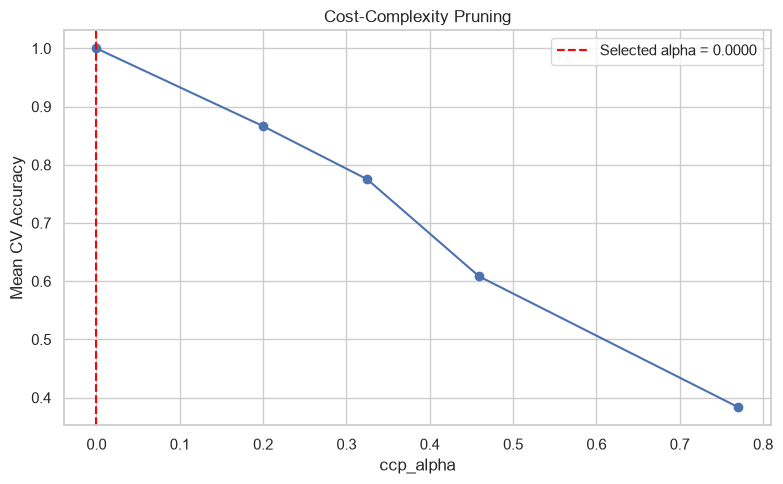

Minimal tree depth: 4
Minimal tree leaves: 6
Minimal tree nodes: 11
Whole-dataset accuracy: 1.0


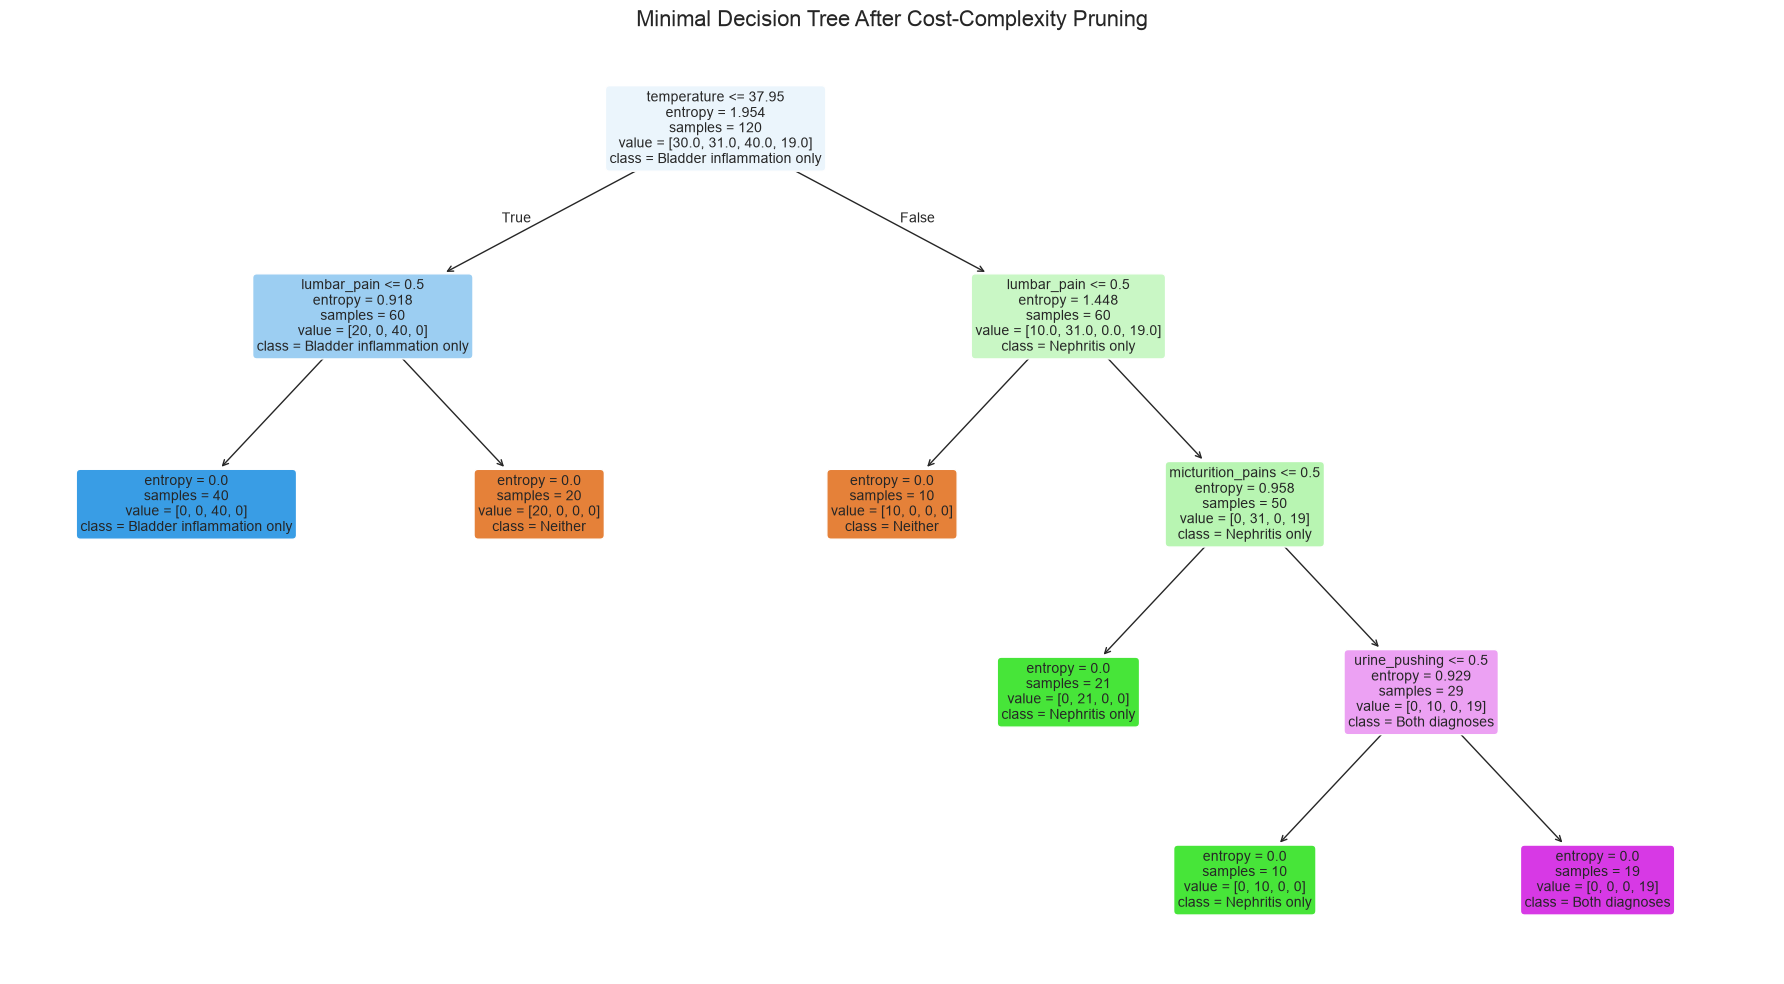

IF-THEN rules for the minimal tree:

Rule 1: IF temperature <= 37.95 AND lumbar_pain = no THEN diagnosis = Bladder inflammation only (samples = 40)
Rule 2: IF temperature <= 37.95 AND lumbar_pain = yes THEN diagnosis = Neither (samples = 20)
Rule 3: IF temperature > 37.95 AND lumbar_pain = no THEN diagnosis = Neither (samples = 10)
Rule 4: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = no THEN diagnosis = Nephritis only (samples = 21)
Rule 5: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = no THEN diagnosis = Nephritis only (samples = 10)
Rule 6: IF temperature > 37.95 AND lumbar_pain = yes AND micturition_pains = yes AND urine_pushing = yes THEN diagnosis = Both diagnoses (samples = 19)


In [5]:
from sklearn.model_selection import StratifiedKFold #keep four diagnosis classes represented in each fold

pruning_path = full_tree.cost_complexity_pruning_path(X_diagnosis, y_powerset)
candidate_alphas = pruning_path.ccp_alphas
pruning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# eval every available pruning strength
pruning_rows = []

for ccp_alpha in candidate_alphas:
    candidate_tree = DecisionTreeClassifier(criterion="entropy", ccp_alpha=ccp_alpha, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(candidate_tree, X_diagnosis, y_powerset, cv=pruning_cv, scoring="accuracy")

    candidate_tree.fit(X_diagnosis, y_powerset)

    pruning_rows.append(
        {
            "ccp_alpha": ccp_alpha,
            "Mean CV Accuracy": cv_scores.mean(),
            "CV Standard Deviation": cv_scores.std(),
            "Tree Depth": candidate_tree.get_depth(),
            "Number of Leaves": candidate_tree.get_n_leaves(),
            "Number of Nodes": candidate_tree.tree_.node_count
        }
    )

pruning_results = pd.DataFrame(pruning_rows)

print("Cost-complexity pruning results:")
display(pruning_results.round(4))
best_cv_accuracy = pruning_results["Mean CV Accuracy"].max() #largest alpha among the models tied for best cv acc
best_candidates = pruning_results[np.isclose(pruning_results["Mean CV Accuracy"], best_cv_accuracy)]
selected_alpha = best_candidates.sort_values("ccp_alpha").iloc[-1]["ccp_alpha"]
print("Selected ccp_alpha:", round(selected_alpha, 6))
print("Best mean CV accuracy:", round(best_cv_accuracy, 4))

plt.figure(figsize=(8, 5)) # cv accuracy for each pruning strength
plt.plot(pruning_results["ccp_alpha"], pruning_results["Mean CV Accuracy"], marker="o")
plt.axvline(selected_alpha, color="red", linestyle="--", label=f"Selected alpha = {selected_alpha:.4f}")
plt.xlabel("ccp_alpha")
plt.ylabel("Mean CV Accuracy")
plt.title("Cost-Complexity Pruning")
plt.legend()
plt.tight_layout()
plt.show()

# fit selected min tree on whole ds
minimal_tree = DecisionTreeClassifier(criterion="entropy", ccp_alpha=selected_alpha, random_state=RANDOM_STATE)
minimal_tree.fit(X_diagnosis, y_powerset)
minimal_tree_predictions = minimal_tree.predict(X_diagnosis)
minimal_tree_accuracy = accuracy_score(y_powerset, minimal_tree_predictions)
print("Minimal tree depth:", minimal_tree.get_depth())
print("Minimal tree leaves:", minimal_tree.get_n_leaves())
print("Minimal tree nodes:", minimal_tree.tree_.node_count)
print("Whole-dataset accuracy:", round(minimal_tree_accuracy, 4))

# plot selected minimal tree
minimal_class_names = [class_name_map[class_code] for class_code in minimal_tree.classes_]

plt.figure(figsize=(18, 10))
plot_tree(minimal_tree, feature_names=diagnosis_feature_names, class_names=minimal_class_names, filled=True, rounded=True, impurity=True, fontsize=10)
plt.title("Minimal Decision Tree After Cost-Complexity Pruning", fontsize=16)
plt.tight_layout()
plt.show()

print("IF-THEN rules for the minimal tree:\n")

print_if_then_rules(minimal_tree, diagnosis_feature_names, class_name_map)

#### Cost-Complexity Pruning Interpretation

The unpruned tree which corresponds to `ccp_alpha = 0` achieved the highest mean five-fold cross-validation accuracy of 1.0000. Every positive value of `ccp_alpha` reduced the tree size, but it also reduced cross-validation accuracy. For example, `ccp_alpha = 0.1996` reduced the tree from 11 to 7 nodes, but its mean cross-validation accuracy decreased to 0.8667.

Therefore, the selected value is `ccp_alpha = 0`. This means that no additional pruning is beneficial. The original tree is already compact and has a depth of 4, 6 leaves, 11 nodes, and only 6 IF-THEN rules. It's both perfectly accurate on the complete dataset and highly interpretable.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [6]:
communities_path = Path("../data/communities.data")
communities_names_path = Path("../data/communities.names")
community_attribute_names = [] #128 col names from the arff section of names file

with communities_names_path.open(encoding="latin-1") as names_file:
    for line in names_file:
        cleaned_line = line.strip()

        if cleaned_line.lower().startswith("@attribute"):
            attribute_name = cleaned_line.split()[1]
            community_attribute_names.append(attribute_name)

print("Number of attribute names:", len(community_attribute_names))

#convert ?s to missing vals
communities_data = pd.read_csv(communities_path, header=None, names=community_attribute_names, na_values="?")

assert communities_data.shape == (1994, 128) #verify complete ds
assert communities_data["ViolentCrimesPerPop"].isna().sum() == 0

print("Complete dataset shape:", communities_data.shape)
print("Total missing values:", communities_data.isna().sum().sum())

#first 1495 - training, rest testing
communities_train_raw = communities_data.iloc[:1495].copy()
communities_test_raw = communities_data.iloc[1495:].copy()

assert communities_train_raw.shape == (1495, 128)
assert communities_test_raw.shape == (499, 128)

print("Training-set shape:", communities_train_raw.shape)
print("Testing-set shape:", communities_test_raw.shape)

preview_columns = community_attribute_names[:10] + ["ViolentCrimesPerPop"]

print("\nFirst five rows:")
display(communities_data[preview_columns].head())

print("\nData type counts:")
display(communities_data.dtypes.value_counts().to_frame(name="Number of Columns"))

Number of attribute names: 128
Complete dataset shape: (1994, 128)
Total missing values: 39202
Training-set shape: (1495, 128)
Testing-set shape: (499, 128)

First five rows:


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.03



Data type counts:


,Number of Columns
float64,125
int64,2
str,1


### (b) Missing values

In [7]:
# remove 5 nonpred cols
nonpredictive_columns = ["state", "county", "community", "communityname", "fold"]
target_name = "ViolentCrimesPerPop"

# sep the preds and target after row split
X_communities_train_raw = communities_train_raw.drop(columns=nonpredictive_columns + [target_name])
X_communities_test_raw = communities_test_raw.drop(columns=nonpredictive_columns + [target_name])
y_communities_train = communities_train_raw[target_name].copy()
y_communities_test = communities_test_raw[target_name].copy()
community_feature_names = X_communities_train_raw.columns.tolist()

assert X_communities_train_raw.shape == (1495, 122)
assert X_communities_test_raw.shape == (499, 122)

print("Number of predictive features:", len(community_feature_names))
print("Training missing values before imputation:", X_communities_train_raw.isna().sum().sum())
print("Testing missing values before imputation:", X_communities_test_raw.isna().sum().sum())

# fts w most missing training vals
missing_summary = pd.DataFrame({"Training Missing": X_communities_train_raw.isna().sum(), "Testing Missing": X_communities_test_raw.isna().sum()})
missing_summary = missing_summary[missing_summary["Training Missing"] > 0].sort_values("Training Missing", ascending=False)

print("\nFeatures containing missing values:")
display(missing_summary)

community_imputer = SimpleImputer(strategy="median") # fit median imp using only train set
X_communities_train = pd.DataFrame(community_imputer.fit_transform(X_communities_train_raw), columns=community_feature_names, index=X_communities_train_raw.index)
X_communities_test = pd.DataFrame(community_imputer.transform(X_communities_test_raw), columns=community_feature_names, index=X_communities_test_raw.index)

assert X_communities_train.shape == (1495, 122)
assert X_communities_test.shape == (499, 122)
assert X_communities_train.isna().sum().sum() == 0
assert X_communities_test.isna().sum().sum() == 0

print("Training missing values after imputation:", X_communities_train.isna().sum().sum())
print("Testing missing values after imputation:", X_communities_test.isna().sum().sum())
print("Imputed training shape:", X_communities_train.shape)
print("Imputed testing shape:", X_communities_test.shape)

Number of predictive features: 122
Training missing values before imputation: 27633
Testing missing values before imputation: 9218

Features containing missing values:


,Training Missing,Testing Missing
PctPolicBlack,1256,419
PctPolicHisp,1256,419
LemasGangUnitDeploy,1256,419
LemasPctPolicOnPatr,1256,419
PolicOperBudg,1256,419
PolicCars,1256,419
PolicAveOTWorked,1256,419
NumKindsDrugsSeiz,1256,419
OfficAssgnDrugUnits,1256,419
PctPolicMinor,1256,419


Training missing values after imputation: 0
Testing missing values after imputation: 0
Imputed training shape: (1495, 122)
Imputed testing shape: (499, 122)


### (c) Plot a correlation matrix

Correlation matrix shape: (122, 122)


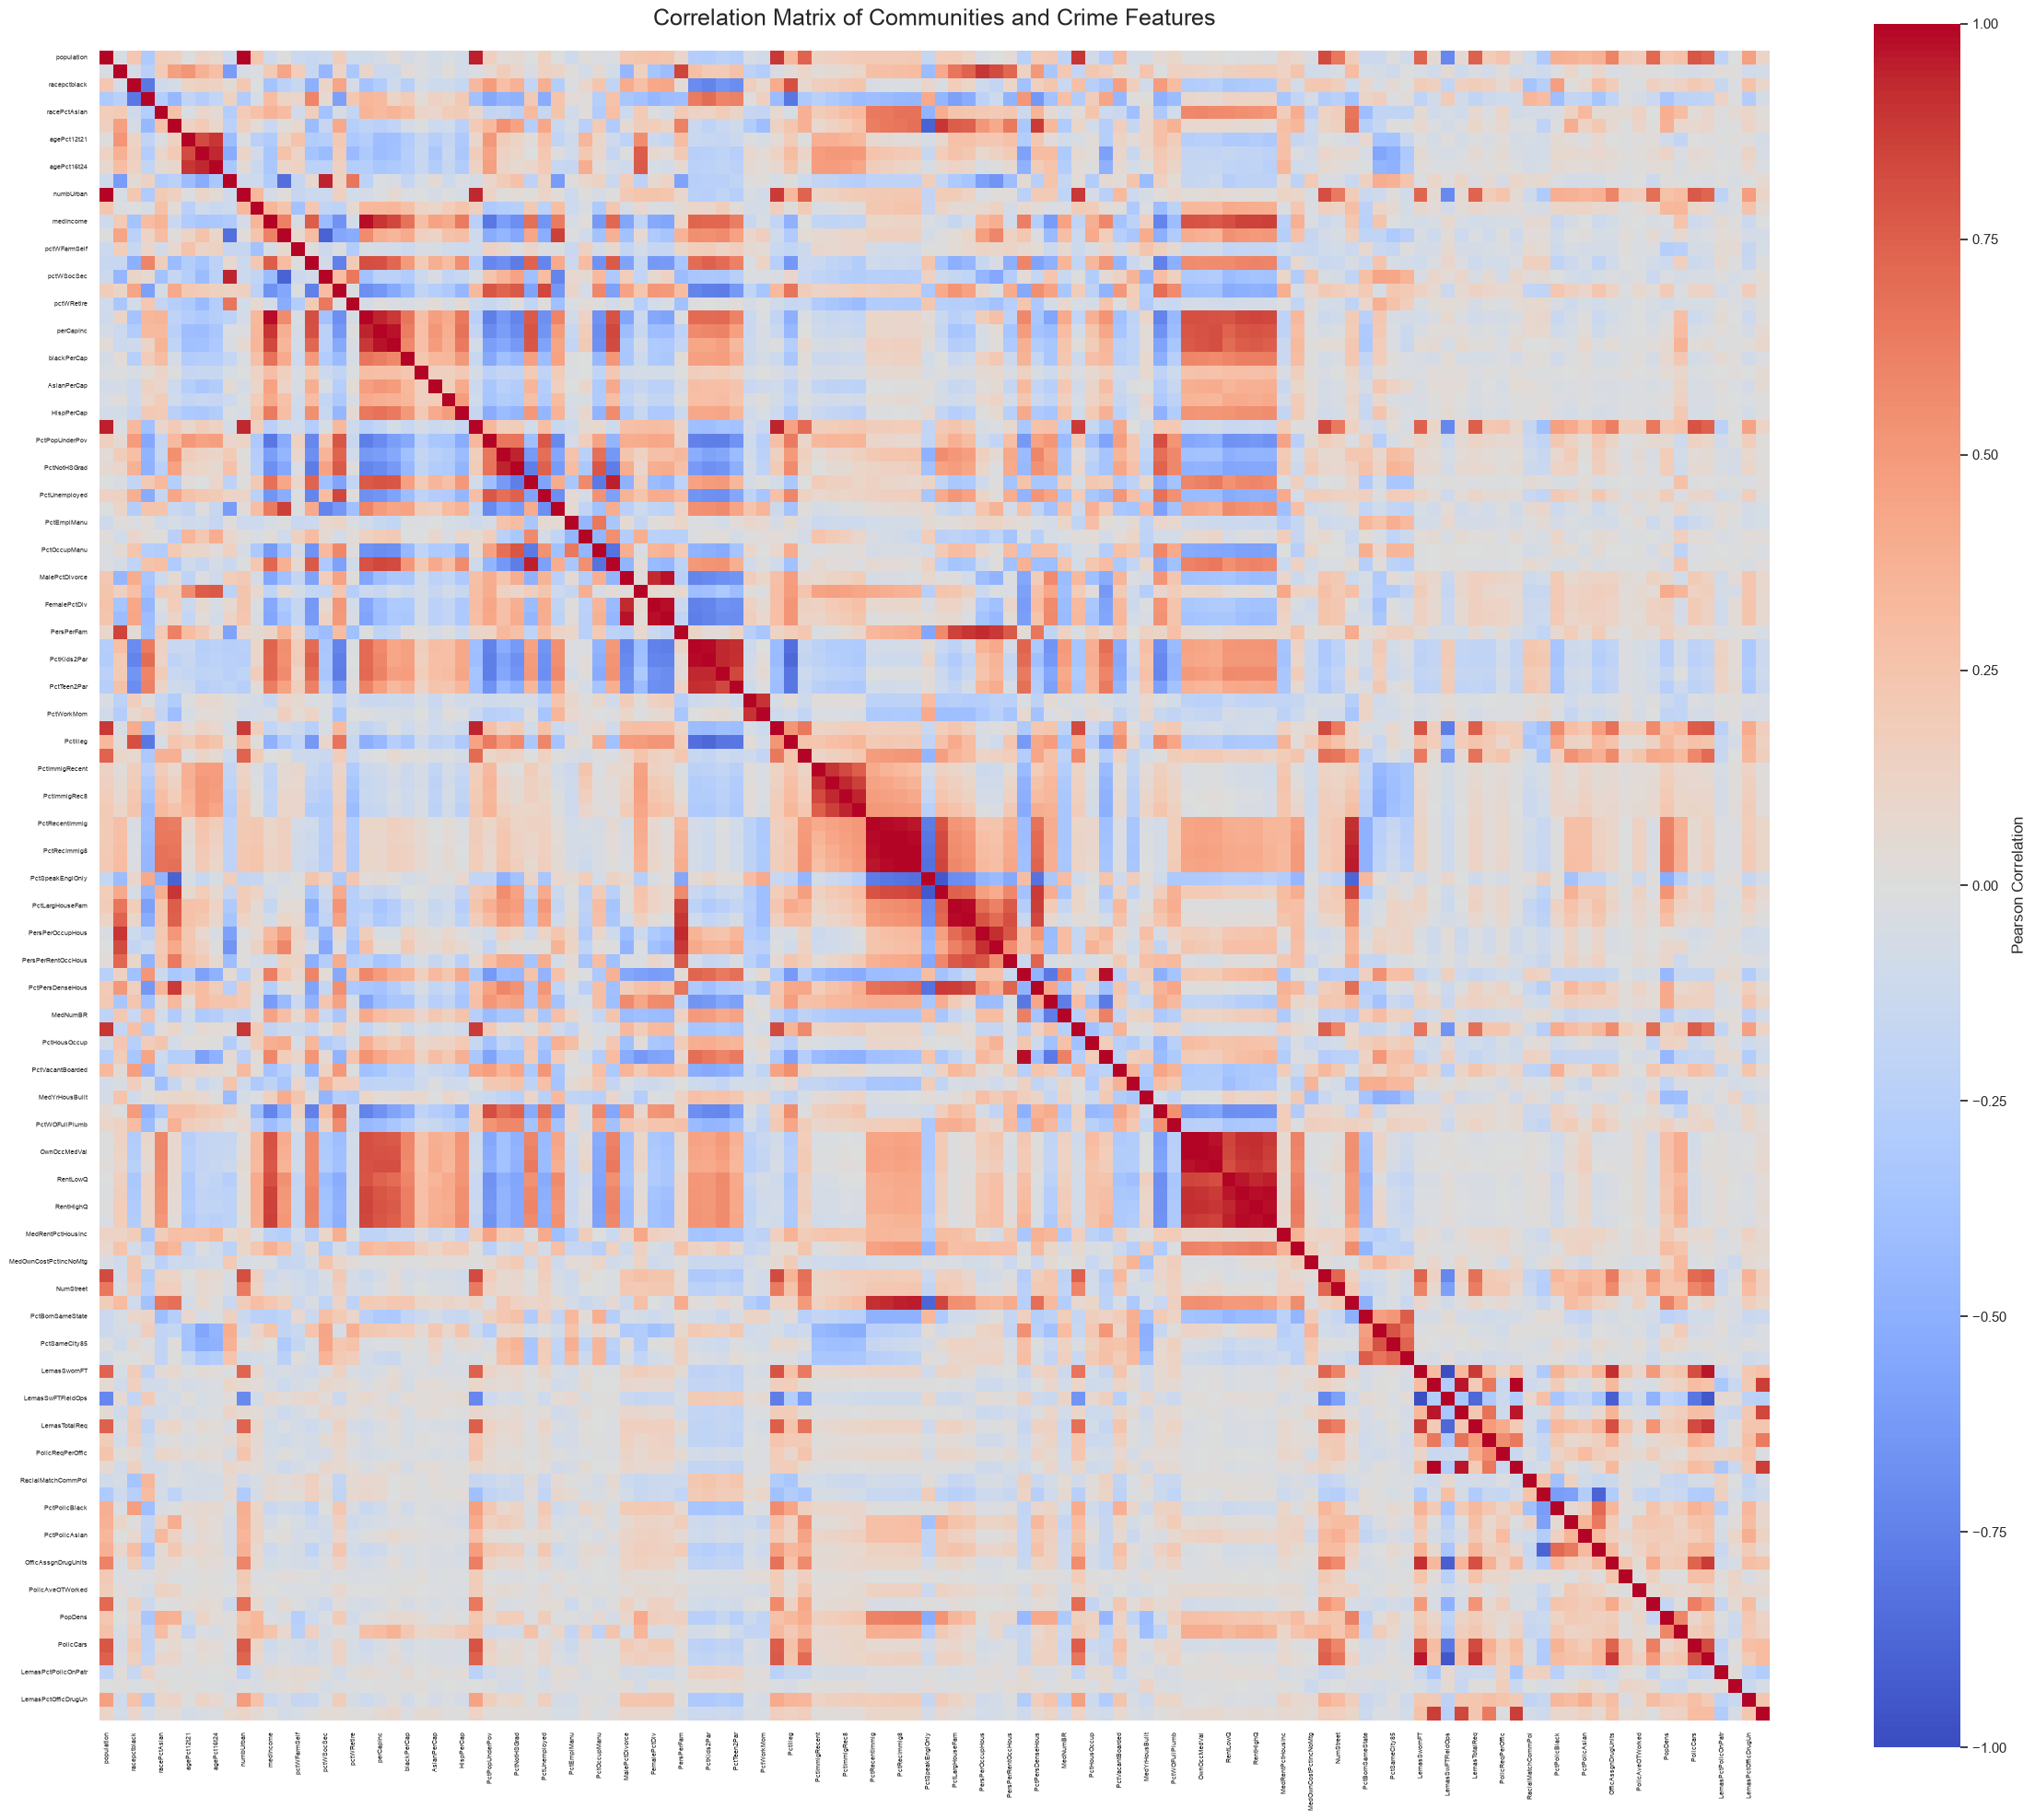

In [8]:
X_communities_all = pd.concat([X_communities_train, X_communities_test], axis=0).sort_index() #combine the imputed train and test preds analysis
assert X_communities_all.shape == (1994, 122)

# calculate correlations among all predictive features
community_correlation_matrix = X_communities_all.corr()

print("Correlation matrix shape:", community_correlation_matrix.shape)
plt.figure(figsize=(24, 20))
sns.heatmap(community_correlation_matrix, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"label": "Pearson Correlation"})
plt.title("Correlation Matrix of Communities and Crime Features", fontsize=18, pad=20)
plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [9]:
community_feature_means = X_communities_all.mean() #calc mean and sample std dev for every ft
community_feature_sample_std = X_communities_all.std(ddof=1)

# calculate cv = sample std dev / mean
community_cv = (community_feature_sample_std / community_feature_means)

#table ranked from highest to lowest cv
community_cv_table = pd.DataFrame({"Mean": community_feature_means, "Sample Standard Deviation": community_feature_sample_std, "CV": community_cv}).sort_values("CV", ascending=False)

assert community_cv_table.shape == (122, 3)
assert np.isfinite(community_cv_table["CV"]).all()

print("Coefficient of Variation for all predictive features:")

with pd.option_context("display.max_rows", None):
    display(community_cv_table.round(4))

print("\nTop 11 features by CV:")
display(community_cv_table.head(11).round(4))

Coefficient of Variation for all predictive features:


,Mean,Sample Standard Deviation,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017



Top 11 features by CV:


,Mean,Sample Standard Deviation,CV
PctPolicAsian,0.0184,0.1001,5.4478
NumStreet,0.0228,0.1004,4.4077
NumInShelters,0.0294,0.1026,3.4855
NumIlleg,0.0363,0.1087,2.9942
NumImmig,0.0301,0.0872,2.9005
LemasPctOfficDrugUn,0.0941,0.2403,2.5553
NumUnderPov,0.0555,0.1279,2.3050
population,0.0576,0.1269,2.2035
LemasSwornFT,0.0279,0.0581,2.0807
numbUrban,0.0641,0.1283,2.0017


### (e) Scatter plots and box plots for highest CV features

Number of selected features: 11
Selected highest-CV features:
1. PctPolicAsian
2. NumStreet
3. NumInShelters
4. NumIlleg
5. NumImmig
6. LemasPctOfficDrugUn
7. NumUnderPov
8. population
9. LemasSwornFT
10. numbUrban
11. HousVacant


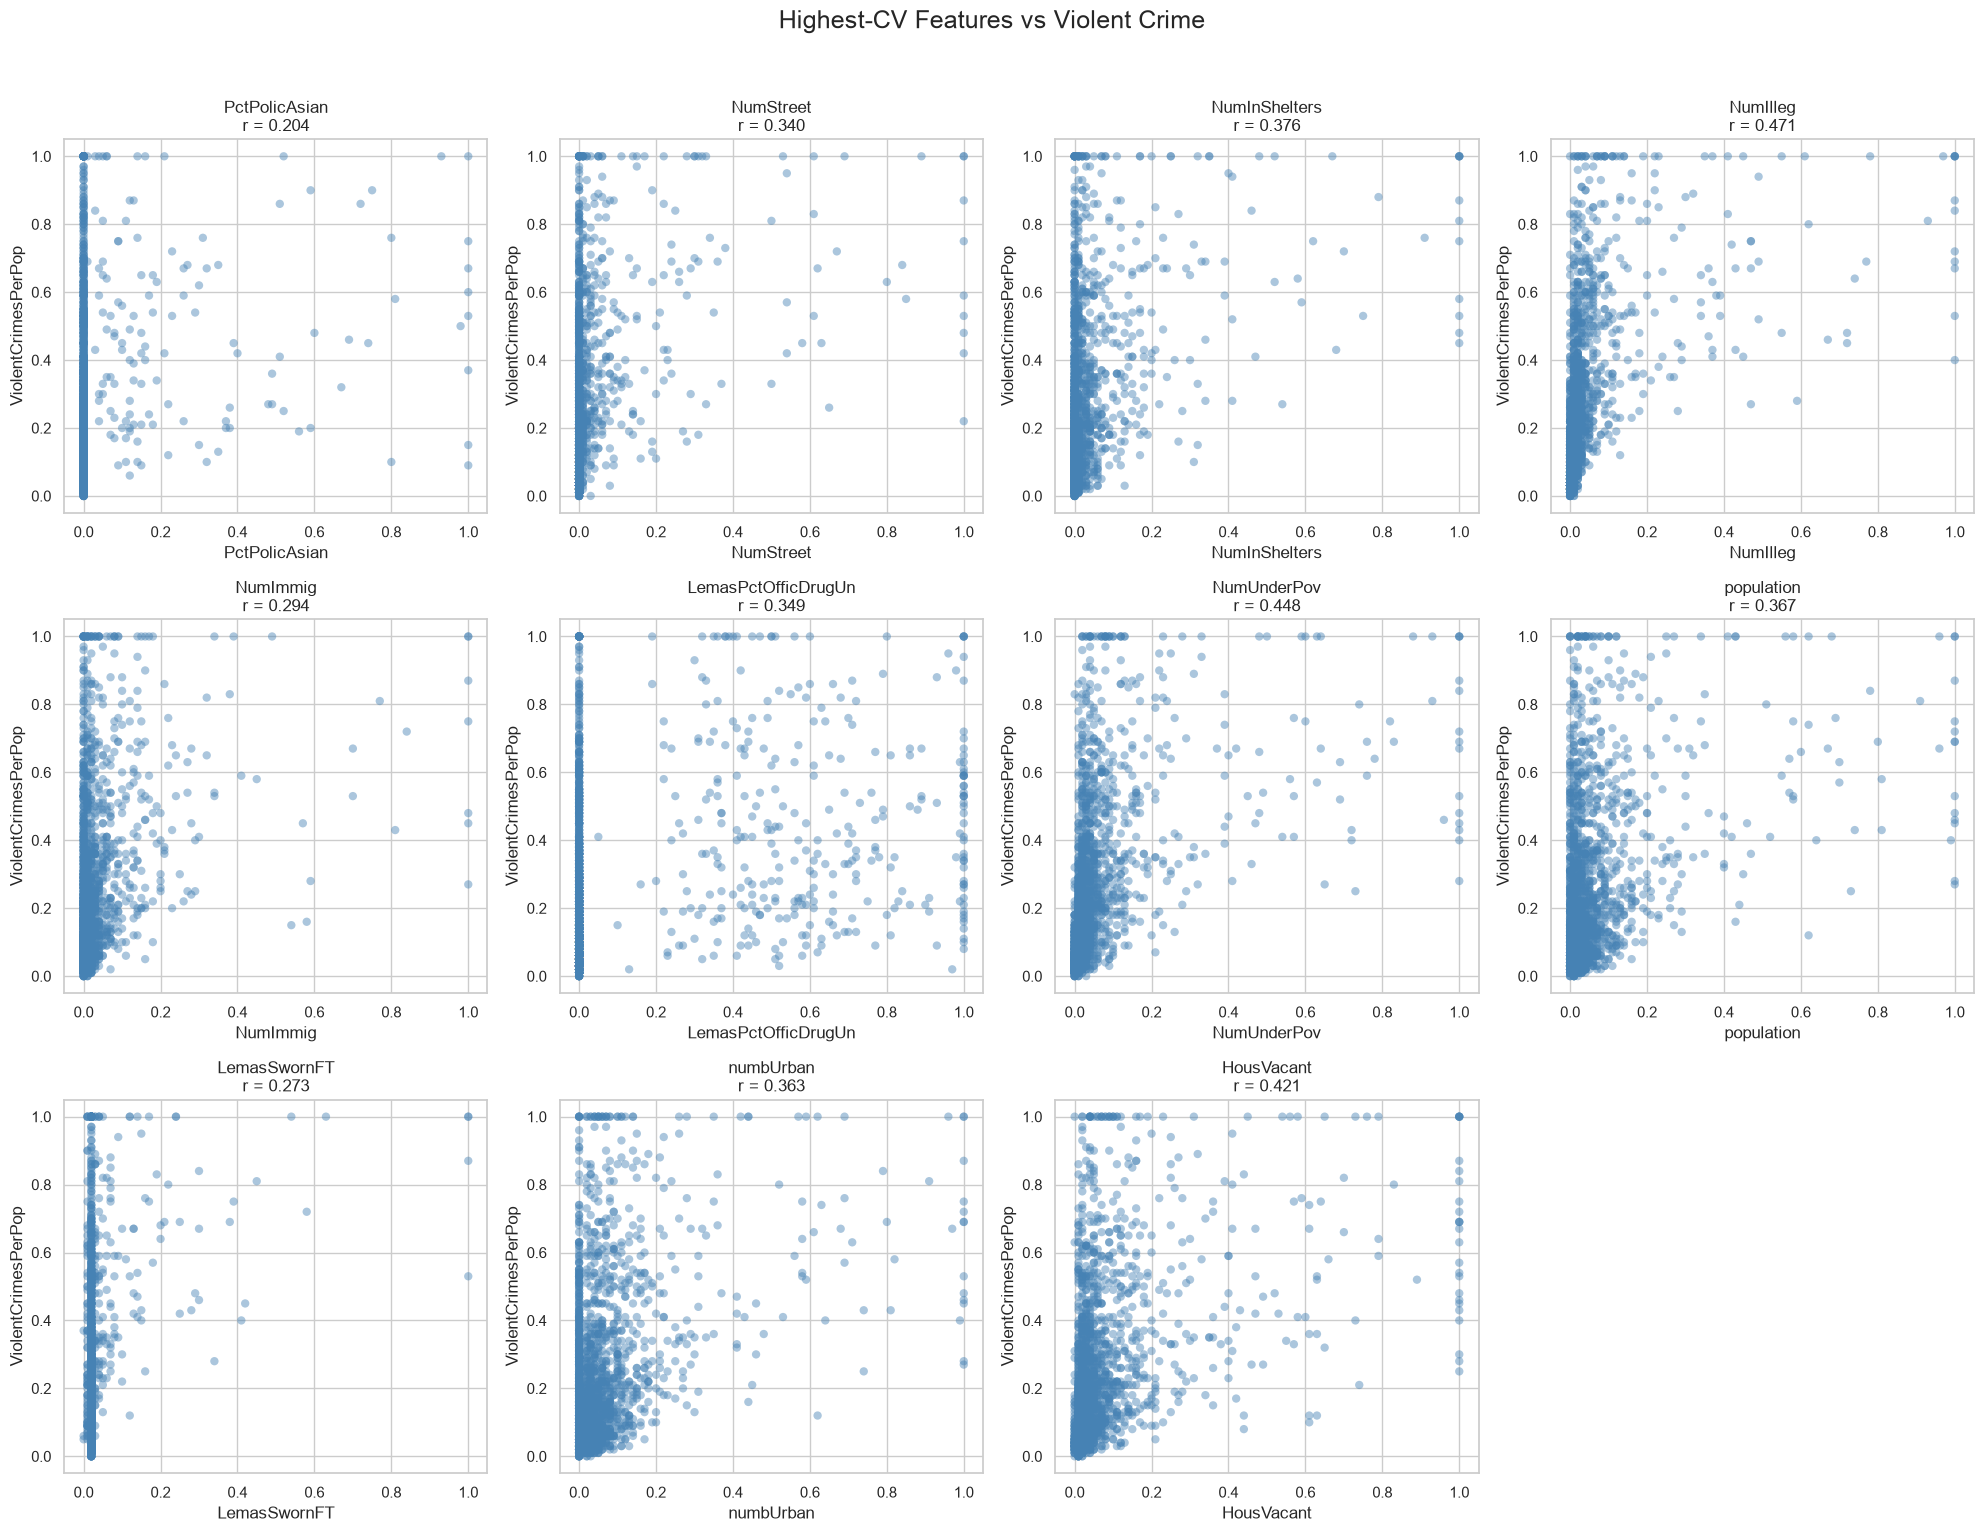

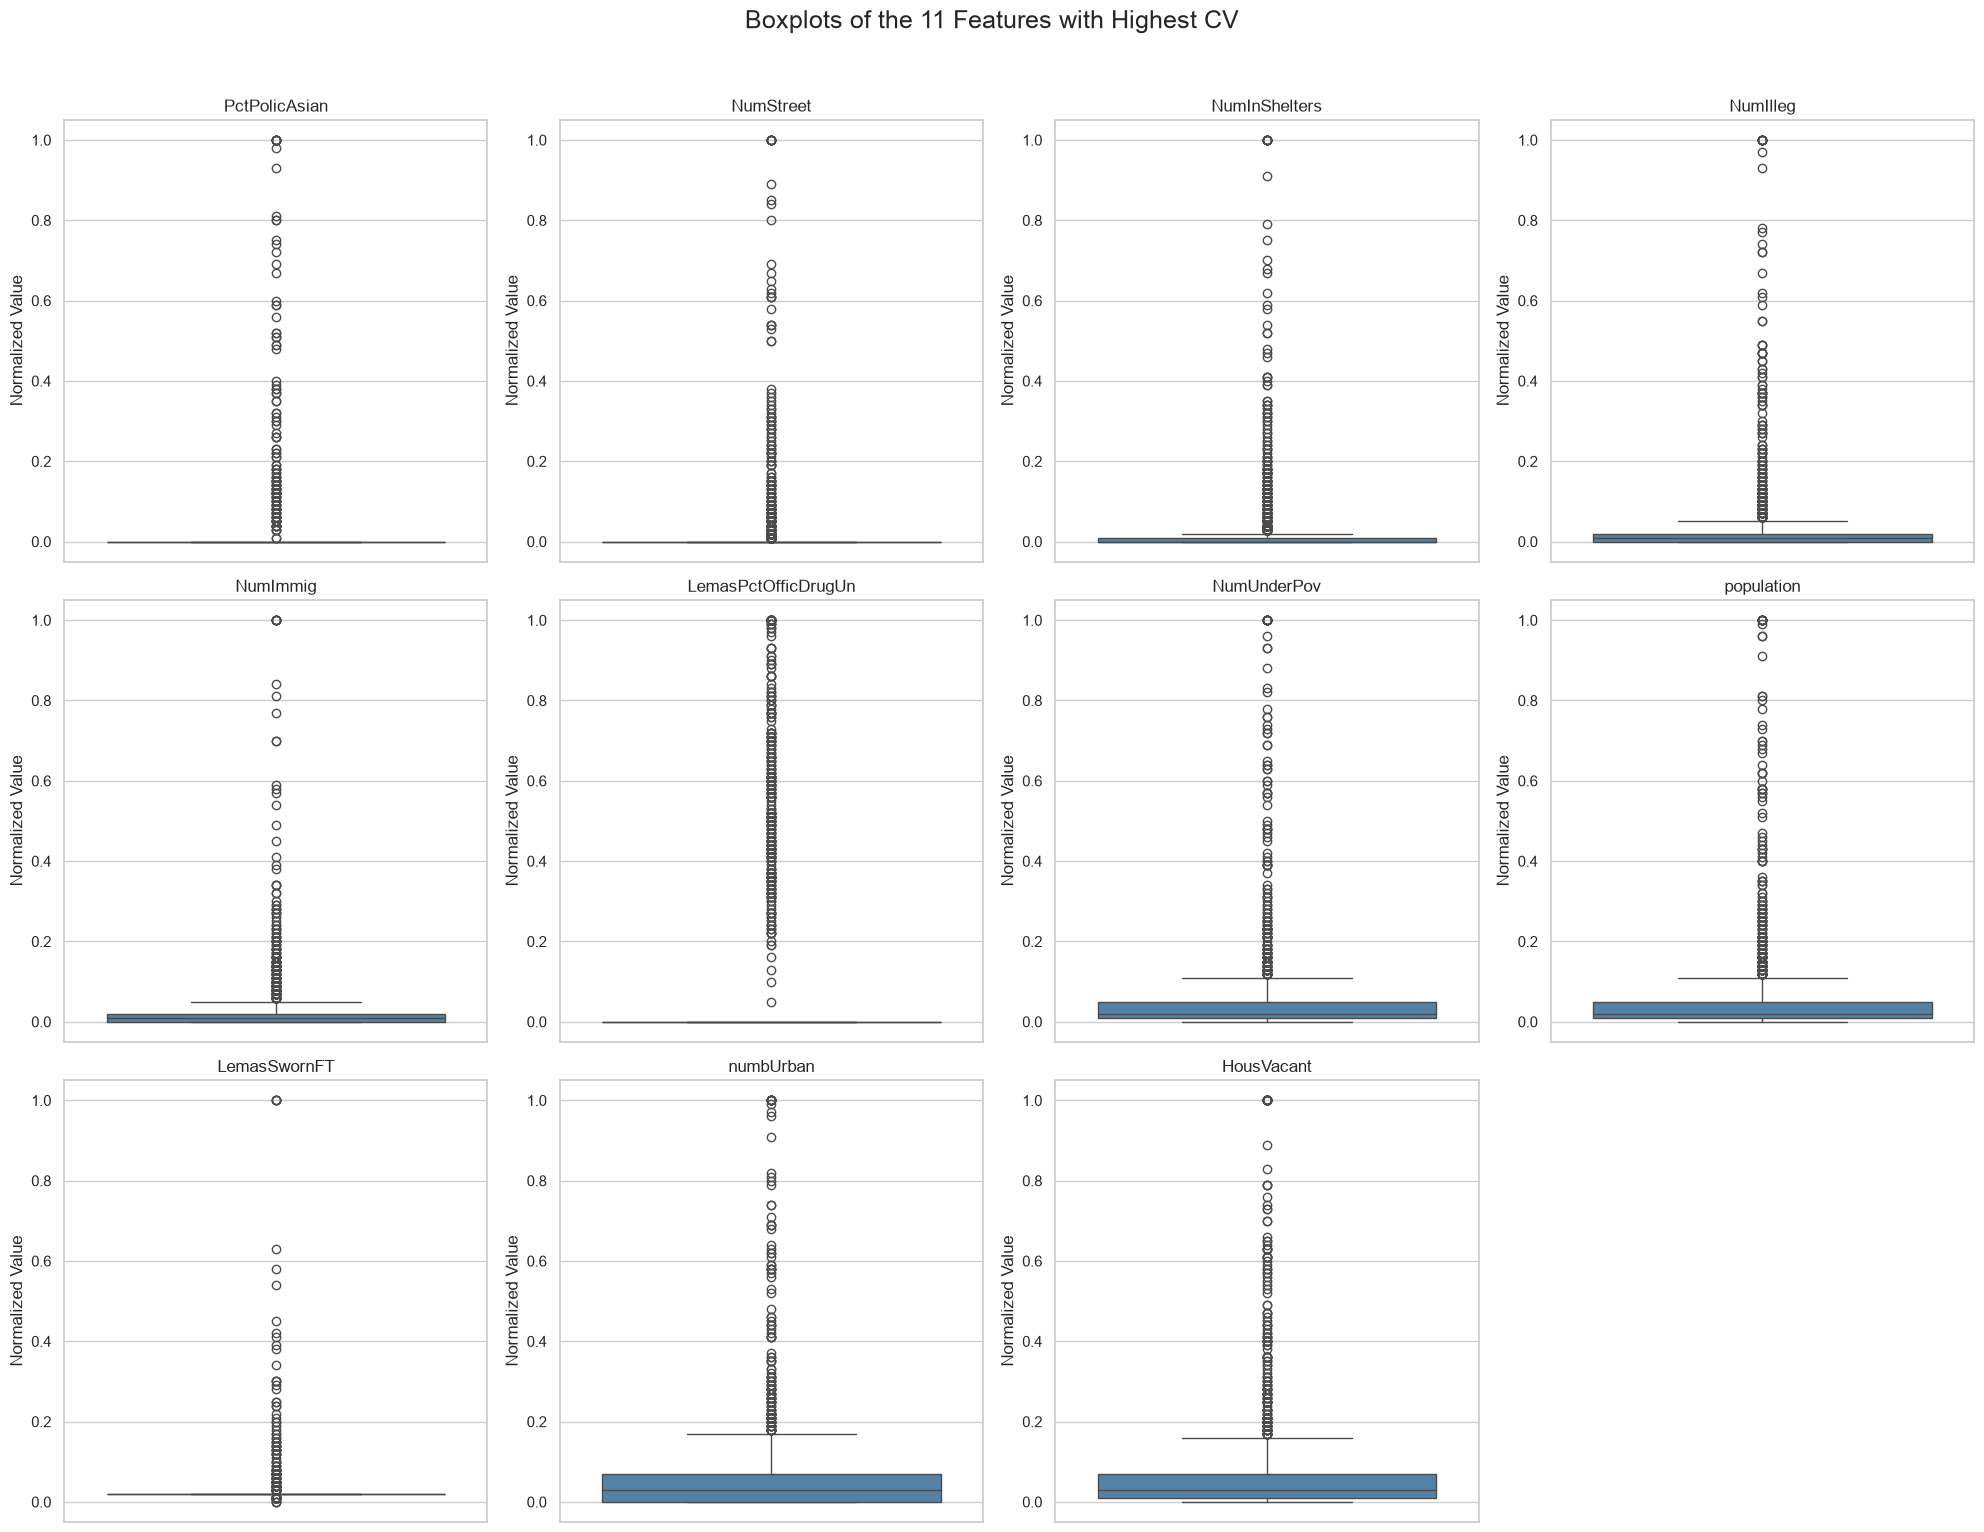

In [10]:
# select floor(sqrt(128)) = 11 features with the highest cv
number_of_high_cv_features = int(np.floor(np.sqrt(128)))
highest_cv_features = community_cv_table.head(number_of_high_cv_features).index.tolist()

print("Number of selected features:", number_of_high_cv_features)
print("Selected highest-CV features:")

for feature_number, feature_name in enumerate(highest_cv_features, start=1):
    print(f"{feature_number}. {feature_name}")

# combine train and test targs for descriptive plots
y_communities_all = pd.concat([y_communities_train, y_communities_test], axis=0).sort_index()

# scatter plots of each selected feature vs violent crime
figure, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for axis, feature_name in zip(axes, highest_cv_features):
    axis.scatter(X_communities_all[feature_name], y_communities_all, alpha=0.45, color="steelblue", edgecolor="none")

    feature_target_correlation = np.corrcoef(X_communities_all[feature_name], y_communities_all)[0, 1]
    axis.set_title(f"{feature_name}\nr = {feature_target_correlation:.3f}")
    axis.set_xlabel(feature_name)
    axis.set_ylabel("ViolentCrimesPerPop")

#unused 12th subplot
for unused_axis in axes[len(highest_cv_features):]:
    unused_axis.set_visible(False)

figure.suptitle("Highest-CV Features vs Violent Crime", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

# boxplots for the same 11 features
figure, axes = plt.subplots(3, 4, figsize=(20, 15))
axes = axes.flatten()

for axis, feature_name in zip(axes, highest_cv_features):
    sns.boxplot(y=X_communities_all[feature_name], ax=axis, color="steelblue")
    axis.set_title(feature_name)
    axis.set_ylabel("Normalized Value")

for unused_axis in axes[len(highest_cv_features):]: #unused 12th subplot
    unused_axis.set_visible(False)

figure.suptitle("Boxplots of the 11 Features with Highest CV", fontsize=18, y=1.02)
plt.tight_layout()
plt.show()

#### Highest-CV Feature Plot Interpretation

The 11 features with the highest coefficients of variation are `PctPolicAsian`, `NumStreet`, `NumInShelters`, `NumIlleg`, `NumImmig`, `LemasPctOfficDrugUn`, `NumUnderPov`, `population`, `LemasSwornFT`, `numbUrban`, and `HousVacant`.

The boxplots show that most of these features are strongly right-skewed. Many communities have values near zero, while a smaller number of communities have much larger values that seem to be potential outliers. This distribution explains why these features have large coefficients of variation. It's because their standard deviations are large relative to their small means.

The scatter plots shows that several features have moderate positive relationships with violent crime. Among the selected features, `NumIlleg`, `NumUnderPov`, and `HousVacant` show the clearest positive relationships, with correlations of 0.471, 0.448, and 0.421, respectively. `NumInShelters`, `population`, `numbUrban`, and `NumStreet` also seem to have positive relationships, but the observations are widely dispersed.

Statistical significance can't be determined from these scatter plots alone since the plots do not provide p-values and do not control for correlations among predictors, confounding variables, outliers, or nonlinear relationships. Therefore, the plots can suggest potentially useful features, but formal inference or model-based analysis would be needed to determine whether they are statistically significant.

### (f) Fit a linear model

In [11]:
least_squares_model = LinearRegression() # fit ordinary least squares w imputed training data
least_squares_model.fit(X_communities_train, y_communities_train)

least_squares_predictions = least_squares_model.predict(X_communities_test) # predict violent crime values for the test set

# use mse as test error
least_squares_test_mse = mean_squared_error(y_communities_test, least_squares_predictions)
least_squares_test_rmse = np.sqrt(least_squares_test_mse)
least_squares_test_r_squared = least_squares_model.score(X_communities_test, y_communities_test)

print("Least-squares test MSE:", round(least_squares_test_mse, 6))
print("Least-squares test RMSE:", round(least_squares_test_rmse, 6))
print("Least-squares test R-squared:", round(least_squares_test_r_squared, 4))

Least-squares test MSE: 0.017966
Least-squares test RMSE: 0.134038
Least-squares test R-squared: 0.6222


### (g) Fit a ridge regression model

In [12]:
ridge_alphas = np.logspace(-4, 4, 100) #range of possible ridge regul strenghts

# select lambda using 5-fold cv on the training set
ridge_model = RidgeCV(alphas=ridge_alphas, cv=5, scoring="neg_mean_squared_error")
ridge_model.fit(X_communities_train, y_communities_train)

# eval selected ridge model on the test set
ridge_predictions = ridge_model.predict(X_communities_test)
ridge_test_mse = mean_squared_error(y_communities_test, ridge_predictions)
ridge_test_rmse = np.sqrt(ridge_test_mse)
ridge_test_r_squared = ridge_model.score(X_communities_test, y_communities_test)

print("Selected Ridge lambda:", round(ridge_model.alpha_, 6))
print("Ridge test MSE:", round(ridge_test_mse, 6))
print("Ridge test RMSE:", round(ridge_test_rmse, 6))
print("Ridge test R-squared:", round(ridge_test_r_squared, 4))

Selected Ridge lambda: 2.31013
Ridge test MSE: 0.017516
Ridge test RMSE: 0.132349
Ridge test R-squared: 0.6317


### (h) Fit a LASSO model

In [15]:
#range of possible lasso reg strengths
lasso_alphas = np.logspace(-5, 0, 200)

# fit lasso cv using the imputed but unstandardized features
lasso_unstandardized_model = LassoCV(alphas=lasso_alphas, cv=5, random_state=RANDOM_STATE, max_iter=100000, n_jobs=-1)
lasso_unstandardized_model.fit(X_communities_train, y_communities_train)
lasso_unstandardized_predictions = (lasso_unstandardized_model.predict(X_communities_test))
lasso_unstandardized_mse = mean_squared_error(y_communities_test, lasso_unstandardized_predictions)
lasso_unstandardized_rmse = np.sqrt(lasso_unstandardized_mse)
lasso_unstandardized_r_squared = (lasso_unstandardized_model.score(X_communities_test, y_communities_test))

unstandardized_selected_mask = (lasso_unstandardized_model.coef_ != 0) # vars chosen by unstandardized lasso
unstandardized_selected_variables = pd.DataFrame(
    {
        "Feature": np.array(community_feature_names)[unstandardized_selected_mask],
        "Coefficient": lasso_unstandardized_model.coef_[unstandardized_selected_mask]
    }
).sort_values("Coefficient", key=abs, ascending=False)

#standardize using train set stats only
lasso_scaler = StandardScaler()

X_communities_train_standardized = (lasso_scaler.fit_transform(X_communities_train))
X_communities_test_standardized = (lasso_scaler.transform(X_communities_test))

# fit lasso cv using the standardized features
lasso_standardized_model = LassoCV(alphas=lasso_alphas, cv=5, random_state=RANDOM_STATE, max_iter=100000, n_jobs=-1)
lasso_standardized_model.fit(X_communities_train_standardized, y_communities_train)
lasso_standardized_predictions = (lasso_standardized_model.predict(X_communities_test_standardized))
lasso_standardized_mse = mean_squared_error(y_communities_test, lasso_standardized_predictions)
lasso_standardized_rmse = np.sqrt(lasso_standardized_mse)
lasso_standardized_r_squared = (lasso_standardized_model.score(X_communities_test_standardized, y_communities_test))

standardized_selected_mask = (lasso_standardized_model.coef_ != 0) #id variables chosen by standardized lasso

standardized_selected_variables = pd.DataFrame(
    {
        "Feature": np.array(community_feature_names)[standardized_selected_mask],
        "Coefficient": lasso_standardized_model.coef_[standardized_selected_mask]
    }
).sort_values("Coefficient", key=abs, ascending=False)

# compare lasso modesl
lasso_comparison = pd.DataFrame(
    {
        "Model": ["LASSO without standardization", "LASSO with standardization"],
        "Selected Lambda": [lasso_unstandardized_model.alpha_, lasso_standardized_model.alpha_],
        "Test MSE": [lasso_unstandardized_mse, lasso_standardized_mse],
        "Test RMSE": [lasso_unstandardized_rmse, lasso_standardized_rmse],
        "Test R-squared": [lasso_unstandardized_r_squared, lasso_standardized_r_squared],
        "Selected Variables": [len(unstandardized_selected_variables), len(standardized_selected_variables)]
    }
)

print("LASSO model comparison:")
display(lasso_comparison.round(6))

print("Variables selected without standardization:")
display(unstandardized_selected_variables.reset_index(drop=True).round(6))

print("Variables selected with standardization:")
display(standardized_selected_variables.reset_index(drop=True).round(6))

LASSO model comparison:


,Model,Selected Lambda,Test MSE,Test RMSE,Test R-squared,Selected Variables
0,LASSO without standardization,0.000128,0.017613,0.132714,0.629632,74
1,LASSO with standardization,0.000766,0.017681,0.132970,0.628199,72


Variables selected without standardization:


,Feature,Coefficient
0,racepctblack,0.267105
1,agePct12t29,-0.243492
2,PctPersDenseHous,0.207550
3,PctKids2Par,-0.198108
4,NumStreet,0.156366
...,...,...
69,OwnOccLowQuart,-0.007966
70,PctImmigRec10,-0.003598
71,MedNumBR,0.001952
72,PctBornSameState,-0.001261


Variables selected with standardization:


,Feature,Coefficient
0,racepctblack,0.067236
1,PctKids2Par,-0.040340
2,PctPersDenseHous,0.039602
3,agePct12t29,-0.037987
4,RentLowQ,-0.027493
...,...,...
67,PctTeen2Par,-0.001394
68,PctEmplManu,-0.000817
69,racePctAsian,-0.000817
70,PctImmigRec5,-0.000368


#### LASSO Results and Standardization Comparison

The LASSO model without additional standardization selected a regularization strength of ~ 0.000128 and kept 74 of the 122 predictors. It got a test MSE of 0.017613, a test RMSE of 0.132714, and a test $R^2$ of 0.629632.

The LASSO model fitted to standardized features selected a regularization strength of ~ 0.000766 and kept 72 predictors. It had a test MSE of 0.017681, a test RMSE of 0.132970, and a test $R^2$ of 0.628199.

The unstandardized LASSO performed slightly better on the test set, but the difference is very small. The original Communities and Crime predictors were already normalized to the range from 0 to 1, so additional standardization didn't provide a meaningful improvement. But standardization did produce a slightly sparser model by reducing the number of selected variables from 74 to 72.

For the unstandardized model, some of the largest coefficients in absolute value belong to `racepctblack`, `agePct12t29`, `PctPersDenseHous`, `PctKids2Par`, and `NumStreet`. Because many predictors are correlated, the selected variables and coefficient values should be interpreted as predictive relationships and not causal effects.

### (i) Fit a PCR model

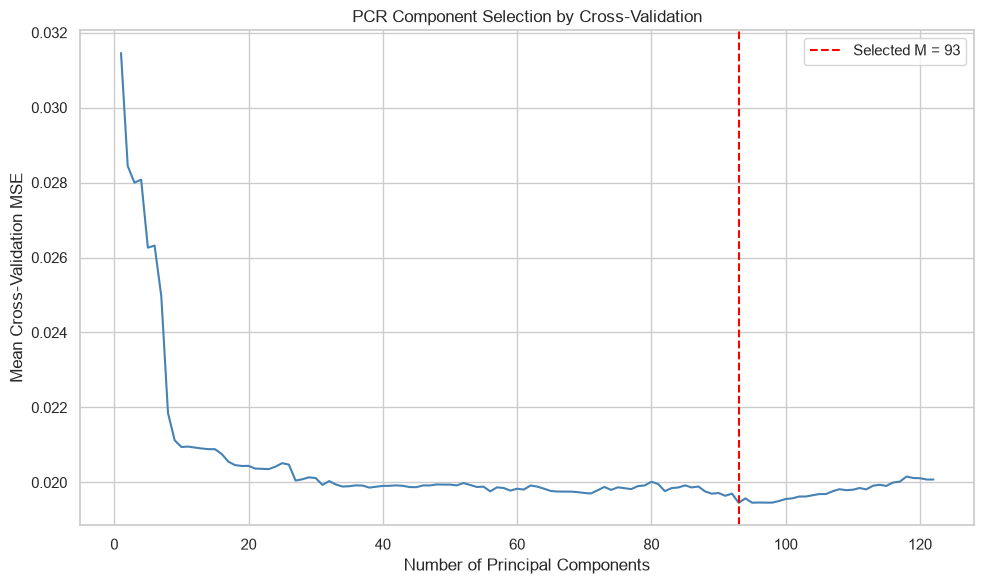

Selected number of components: 93
Best mean CV MSE: 0.019457
PCR test MSE: 0.018264
PCR test RMSE: 0.135145
PCR test R-squared: 0.6159


In [17]:
pcr_pipeline = Pipeline([("scaler", StandardScaler()), ("pca", PCA()), ("regression", LinearRegression())]) #pcr pipeline so scaling and pca areinside each cv fold

# test every possible number of principal components
pcr_component_values = np.arange(1, len(community_feature_names) + 1)
pcr_parameter_grid = {"pca__n_components": pcr_component_values}
pcr_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# num components using cv training mse
pcr_search = GridSearchCV(estimator=pcr_pipeline, param_grid=pcr_parameter_grid, scoring="neg_mean_squared_error", cv=pcr_cv, n_jobs=-1)
pcr_search.fit(X_communities_train, y_communities_train)
selected_pcr_components = (pcr_search.best_params_["pca__n_components"])

pcr_cv_results = pd.DataFrame(pcr_search.cv_results_) #cv errors
pcr_cv_mse = -pcr_cv_results["mean_test_score"]

#plot cv mse against the num componenets
plt.figure(figsize=(10, 6))
plt.plot(pcr_component_values, pcr_cv_mse, color="steelblue")
plt.axvline(selected_pcr_components, color="red", linestyle="--", label=f"Selected M = {selected_pcr_components}")

plt.xlabel("Number of Principal Components")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("PCR Component Selection by Cross-Validation")
plt.legend()
plt.tight_layout()
plt.show()

# eval selected pcr model on test set
pcr_predictions = pcr_search.predict(X_communities_test)
pcr_test_mse = mean_squared_error(y_communities_test, pcr_predictions)
pcr_test_rmse = np.sqrt(pcr_test_mse)
pcr_test_r_squared = (pcr_search.best_estimator_.score(X_communities_test, y_communities_test))

print("Selected number of components:", selected_pcr_components)
print("Best mean CV MSE:", round(-pcr_search.best_score_, 6))
print("PCR test MSE:", round(pcr_test_mse, 6))
print("PCR test RMSE:", round(pcr_test_rmse, 6))
print("PCR test R-squared:", round(pcr_test_r_squared, 4))

#### PCR Results

Cross-validation selected 93 principal components. The selected PCR model got a mean cross-validation MSE of 0.019457, a test MSE of 0.018264, a test RMSE of 0.135145, and a test $R^2$ of 0.6159.

PCR performed slightly worse than least squares, Ridge, and both LASSO models. Although PCA outputs uncorrelated predictors and can reduce
the dimensionality of the data, its components are selected to explain variation in the predictors rather than variation in the response.
Therefore, components that explain substantial predictor variation aren't necessarily the components that best predict violent crime.

### (j) Fit a boosting tree

XGBoost alpha cross-validation results:


,reg_alpha,Mean CV MSE
0,0.000000,0.019861
1,0.000100,0.019908
2,0.000316,0.019953
3,0.001000,0.019930
4,0.003162,0.019805
5,0.010000,0.020023
6,0.031623,0.019727
7,0.100000,0.019688
8,0.316228,0.019526
9,1.000000,0.019700


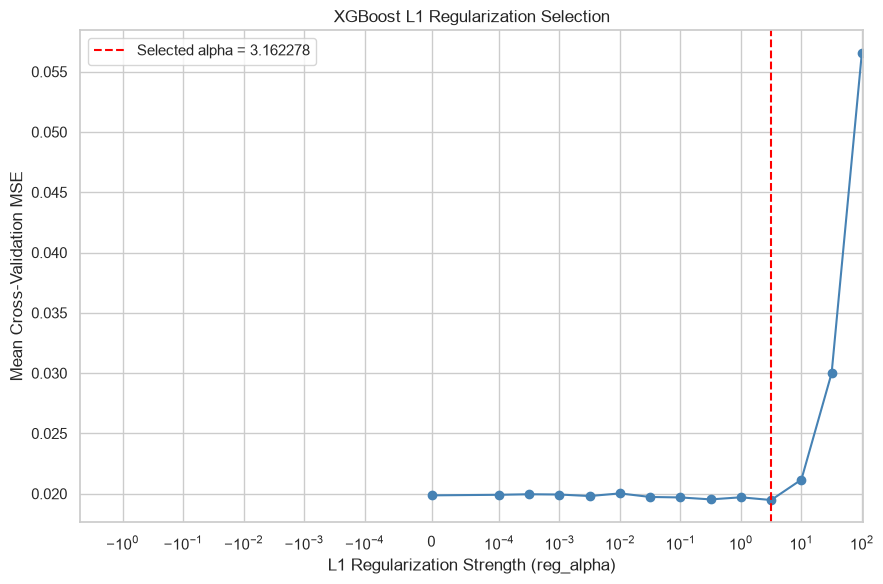

Selected XGBoost alpha: 3.162278
Best mean CV MSE: 0.019473
XGBoost test MSE: 0.015814
XGBoost test RMSE: 0.125753
XGBoost test R-squared: 0.6675


In [18]:
xgboost_alpha_values = np.concatenate(([0.0], np.logspace(-4, 2, 13))) #cand l1 reg strengths

# xgboost reg model
xgboost_model = XGBRegressor(objective="reg:squarederror", n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=1)
xgboost_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# select reg_alpha using cv on the training set
xgboost_search = GridSearchCV(estimator=xgboost_model, param_grid={"reg_alpha": xgboost_alpha_values}, scoring="neg_mean_squared_error", cv=xgboost_cv, n_jobs=-1)
xgboost_search.fit(X_communities_train, y_communities_train)
xgboost_cv_results = pd.DataFrame(xgboost_search.cv_results_) # alpha cv results

xgboost_alpha_results = pd.DataFrame({"reg_alpha": xgboost_cv_results["param_reg_alpha"], "Mean CV MSE": -xgboost_cv_results["mean_test_score"]})
print("XGBoost alpha cross-validation results:")
display(xgboost_alpha_results.round(6))

selected_xgboost_alpha = (xgboost_search.best_params_["reg_alpha"]) #cv error for each candidate alpha
plt.figure(figsize=(9, 6))
plt.plot(xgboost_alpha_results["reg_alpha"], xgboost_alpha_results["Mean CV MSE"], marker="o", color="steelblue")
plt.axvline(selected_xgboost_alpha, color="red", linestyle="--", label=f"Selected alpha = {selected_xgboost_alpha:.6f}")
plt.xscale("symlog", linthresh=0.0001)
plt.xlabel("L1 Regularization Strength (reg_alpha)")
plt.ylabel("Mean Cross-Validation MSE")
plt.title("XGBoost L1 Regularization Selection")
plt.legend()
plt.tight_layout()
plt.show()

# evaluate the selected model on the test set
xgboost_predictions = xgboost_search.predict(X_communities_test)
xgboost_test_mse = mean_squared_error(y_communities_test, xgboost_predictions)
xgboost_test_rmse = np.sqrt(xgboost_test_mse)
xgboost_test_r_squared = (xgboost_search.best_estimator_.score(X_communities_test, y_communities_test))
print("Selected XGBoost alpha:", round(selected_xgboost_alpha, 6))
print("Best mean CV MSE:", round(-xgboost_search.best_score_, 6))
print("XGBoost test MSE:", round(xgboost_test_mse, 6))
print("XGBoost test RMSE:", round(xgboost_test_rmse, 6))
print("XGBoost test R-squared:", round(xgboost_test_r_squared, 4))

#### XGBoost Results

Cross-validation selected an L1 regularization strength of $\alpha=3.162278$. The selected XGBoost model got a mean cross-validation MSE of 0.019473, a test MSE of 0.015814, a test RMSE of 0.125753, and a test $R^2$ of 0.6675.

The cross-validation results show that very large values of `reg_alpha` increase prediction error by a lot. This happens because excessive regularization restricts the model too strongly and leads to underfitting. The selected value gives us the best balance among the candidate regularization strengths.

XGBoost produced the best test performance of the models evaluated in this assignment. Its improvement shows that nonlinear relationships and interactions among the community features contain predictive information that isn't fully represented by the linear regression, Ridge, LASSO, or PCR models.

In [19]:
# compare the test-set performance of all regression models
model_comparison = pd.DataFrame({
    "Model": ["Least Squares", "Ridge", "LASSO without Standardization", "LASSO with Standardization", "PCR", "XGBoost"],
    "Test MSE": [least_squares_test_mse, ridge_test_mse, lasso_unstandardized_mse, lasso_standardized_mse, pcr_test_mse, xgboost_test_mse],
    "Test RMSE": [least_squares_test_rmse, ridge_test_rmse, lasso_unstandardized_rmse, lasso_standardized_rmse, pcr_test_rmse, xgboost_test_rmse],
    "Test R-squared": [least_squares_test_r_squared, ridge_test_r_squared, lasso_unstandardized_r_squared, lasso_standardized_r_squared, pcr_test_r_squared, xgboost_test_r_squared]
})

model_comparison = model_comparison.sort_values("Test MSE").reset_index(drop=True)
print("Final regression model comparison:")
display(model_comparison.round(6))
print(f"\nBest model by test MSE: {model_comparison.loc[0, 'Model']}")

Final regression model comparison:


,Model,Test MSE,Test RMSE,Test R-squared
0,XGBoost,0.015814,0.125753,0.667463
1,Ridge,0.017516,0.132349,0.631666
2,LASSO without Standardization,0.017613,0.132714,0.629632
3,LASSO with Standardization,0.017681,0.132970,0.628199
4,Least Squares,0.017966,0.134038,0.622204
5,PCR,0.018264,0.135145,0.615937



Best model by test MSE: XGBoost


### Final Model Comparison and Conclusion

XGBoost output the best test-set performance, with an MSE of 0.015814, an RMSE of 0.125753, and an $R^2$ of 0.6675. This shows that its nonlinear structure and ability to model feature interactions were useful for predicting violent crime.

Among the linear models, Ridge regression performed best, with a test MSE of 0.017516 and an $R^2$ of 0.6317. Both LASSO models performed about the same to Ridge while producing sparser models through variable selection. Standardization didn't improve LASSO's test performance in this analysis.

Least-squares regression performed decently well but was slightly outperformed by the regularized linear models. PCR had the highest test MSE of the evaluated models, showing that selecting components based on predictor variance didn't keep all of the information most useful for predicting the response.

Overall, XGBoost is the preferred predictive model for this dataset. These results describe predictive associations and shouldn't be interpreted as evidence that the selected community characteristics cause violent crime.